In [1]:
import pandas as pd 
import numpy as np 
import sheryanalysis as sh 
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings    

warnings.filterwarnings('ignore') 

In [2]:
df = pd.read_csv('Global_Superyachts_and_Cruises.csv')

In [3]:
df

,Vessel_ID,Vessel_Name,Type,Builder,Year_Built,Length_meters,Gross_Tonnage,Engine_Type,Top_Speed_knots,Guests_Capacity,Crew_Capacity,Estimated_Value_USD_Millions,Current_Region,Latitude,Longitude
0,64ce98d3,Yacht_Wind_867,Luxury Cruise,Amels,2020,348.8,6368,MTU 20V 4000,26.9,1600,814,1149.30,Mediterranean Sea,34.637352,26.871785
1,53443fc0,Yacht_Wind_149,Superyacht,Oceanco,2021,57.5,1321,Volvo Penta,19.5,50,26,93.19,Persian Gulf,27.498674,52.560493
2,1f7d824d,Yacht_Star_447,Superyacht,Lürssen,2020,129.1,3550,Caterpillar 3516C,32.3,47,33,180.04,Persian Gulf,28.431264,51.035894
3,efda250c,Yacht_Wind_280,Superyacht,Heesen,2010,147.7,3392,Volvo Penta,27.5,39,26,232.14,Persian Gulf,24.425408,53.287280
4,f153e462,Yacht_Aqua_895,Superyacht,Blohm+Voss,2012,176.3,3248,Rolls-Royce Marine,30.7,34,22,223.96,Caribbean Sea,22.347593,-68.690359
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8995,dc708171,Yacht_Star_923,Superyacht,Blohm+Voss,2009,82.4,1294,Wärtsilä 12V,27.0,34,21,108.78,Persian Gulf,27.520373,53.778417
8996,d008c90b,Yacht_Wind_418,Superyacht,Oceanco,2024,119.7,2688,Rolls-Royce Marine,29.6,26,8,160.42,Australian Coast,-32.918521,148.640666
8997,bd81bab4,Yacht_Star_835,Superyacht,Feadship,2008,87.7,1435,Caterpillar 3516C,26.1,15,4,185.29,Mediterranean Sea,36.970128,-4.514002
8998,27129c90,Yacht_Aqua_463,Superyacht,Lürssen,2021,149.7,4301,MTU 20V 4000,33.3,49,20,207.14,South China Sea,5.758824,117.744027


In [4]:
df.columns

Index(['Vessel_ID', 'Vessel_Name', 'Type', 'Builder', 'Year_Built',
       'Length_meters', 'Gross_Tonnage', 'Engine_Type', 'Top_Speed_knots',
       'Guests_Capacity', 'Crew_Capacity', 'Estimated_Value_USD_Millions',
       'Current_Region', 'Latitude', 'Longitude'],
      dtype='str')

In [6]:
df['Type'].value_counts()

Type
Superyacht          5348
Mega Yacht          1868
Expedition Yacht     915
Luxury Cruise        869
Name: count, dtype: int64

In [8]:
cols_to_drop = ['Vessel_ID', 'Vessel_Name', 'Latitude', 'Longitude']
target_var = ['Estimated_Value_USD_Millions']

In [12]:
df.drop(columns=cols_to_drop, inplace=True)

KeyError: "['Vessel_ID', 'Vessel_Name', 'Latitude', 'Longitude'] not found in axis"

In [13]:
df

,Type,Builder,Year_Built,Length_meters,Gross_Tonnage,Engine_Type,Top_Speed_knots,Guests_Capacity,Crew_Capacity,Estimated_Value_USD_Millions,Current_Region
0,Luxury Cruise,Amels,2020,348.8,6368,MTU 20V 4000,26.9,1600,814,1149.30,Mediterranean Sea
1,Superyacht,Oceanco,2021,57.5,1321,Volvo Penta,19.5,50,26,93.19,Persian Gulf
2,Superyacht,Lürssen,2020,129.1,3550,Caterpillar 3516C,32.3,47,33,180.04,Persian Gulf
3,Superyacht,Heesen,2010,147.7,3392,Volvo Penta,27.5,39,26,232.14,Persian Gulf
4,Superyacht,Blohm+Voss,2012,176.3,3248,Rolls-Royce Marine,30.7,34,22,223.96,Caribbean Sea
...,...,...,...,...,...,...,...,...,...,...,...
8995,Superyacht,Blohm+Voss,2009,82.4,1294,Wärtsilä 12V,27.0,34,21,108.78,Persian Gulf
8996,Superyacht,Oceanco,2024,119.7,2688,Rolls-Royce Marine,29.6,26,8,160.42,Australian Coast
8997,Superyacht,Feadship,2008,87.7,1435,Caterpillar 3516C,26.1,15,4,185.29,Mediterranean Sea
8998,Superyacht,Lürssen,2021,149.7,4301,MTU 20V 4000,33.3,49,20,207.14,South China Sea


In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Type                          9000 non-null   str    
 1   Builder                       9000 non-null   str    
 2   Year_Built                    9000 non-null   int64  
 3   Length_meters                 9000 non-null   float64
 4   Gross_Tonnage                 9000 non-null   int64  
 5   Engine_Type                   9000 non-null   str    
 6   Top_Speed_knots               9000 non-null   float64
 7   Guests_Capacity               9000 non-null   int64  
 8   Crew_Capacity                 9000 non-null   int64  
 9   Estimated_Value_USD_Millions  9000 non-null   float64
 10  Current_Region                9000 non-null   str    
dtypes: float64(3), int64(4), str(4)
memory usage: 1.2 MB


In [24]:
num_cols = df.select_dtypes(include=['int64' , 'float64'])

In [26]:
num_cols = num_cols.columns.to_list()
num_cols.remove('Estimated_Value_USD_Millions')


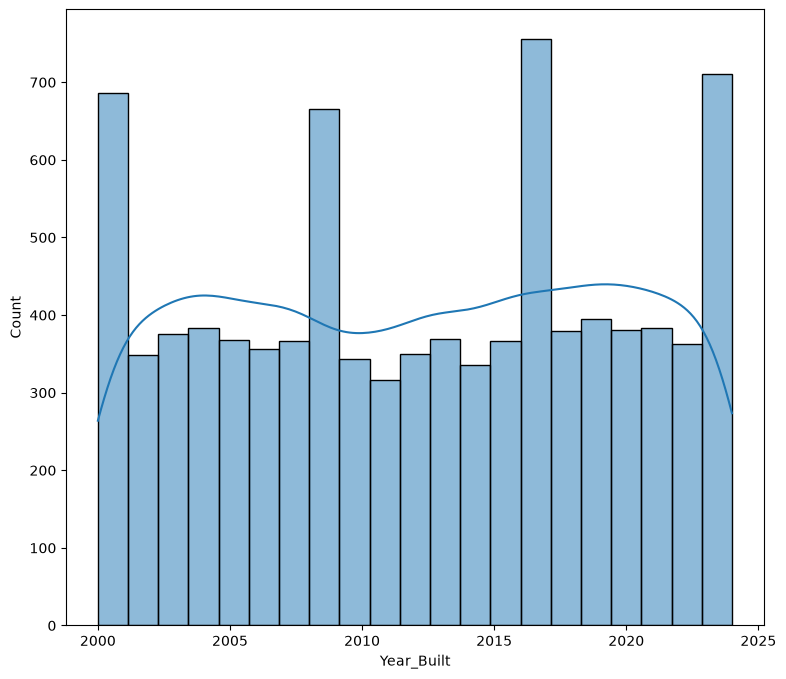

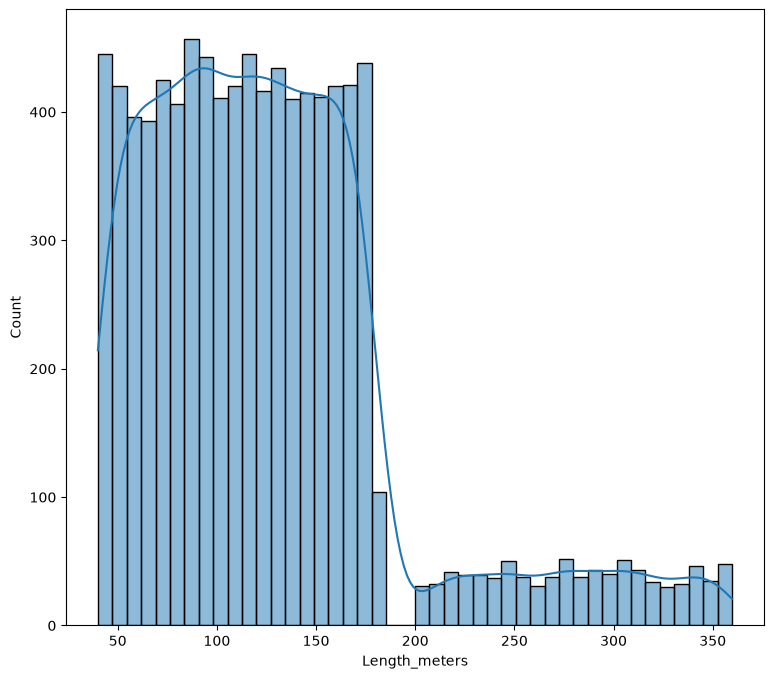

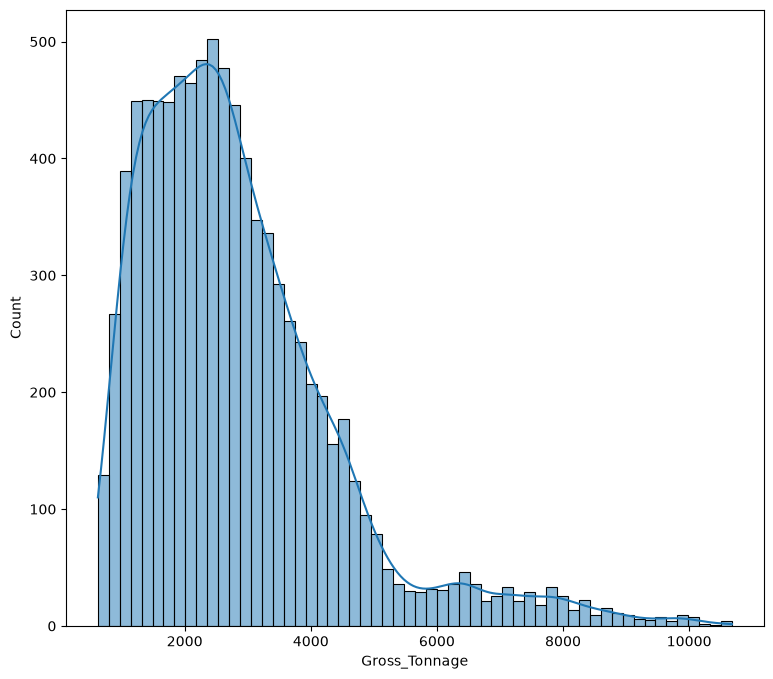

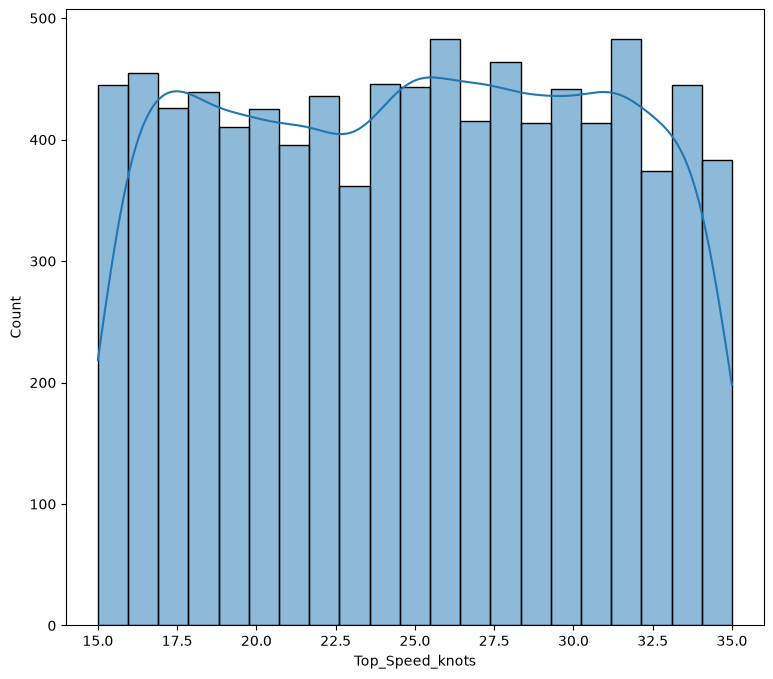

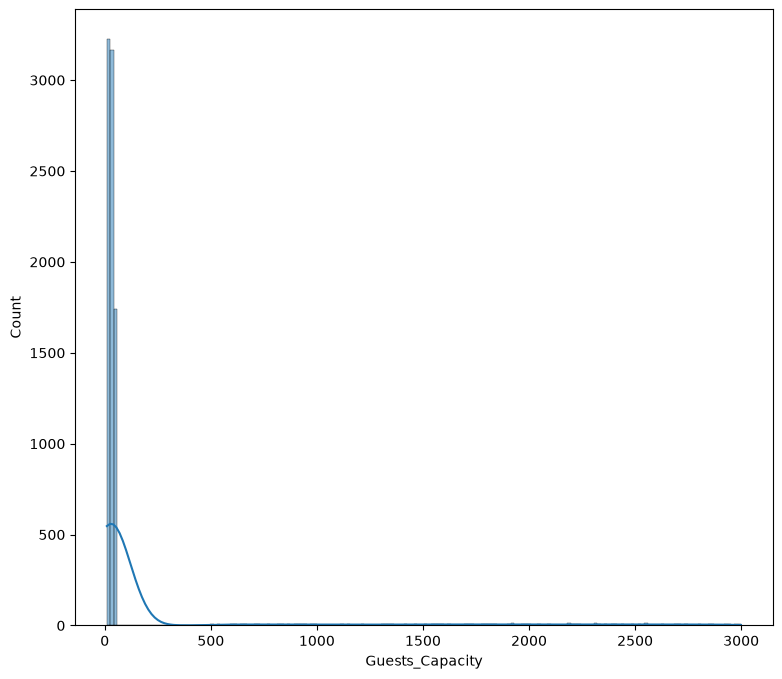

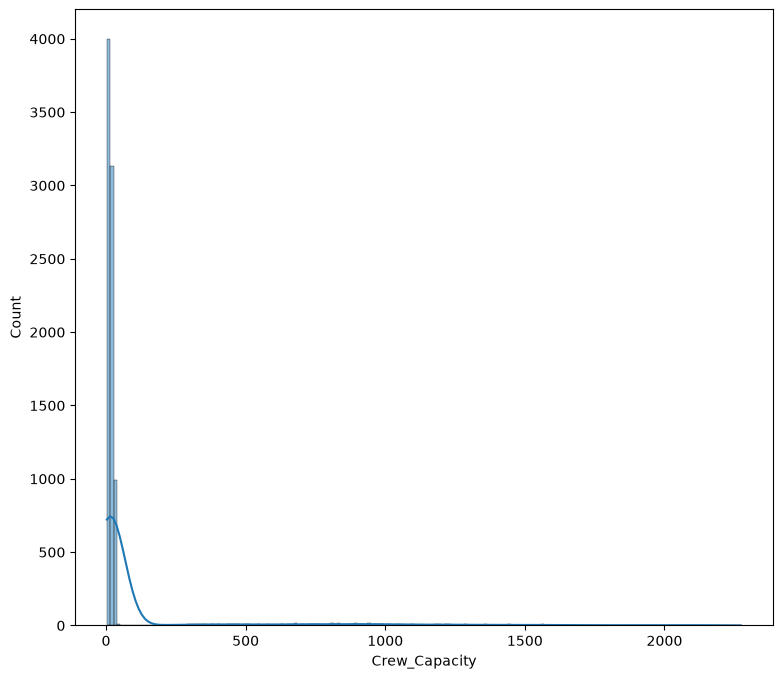

In [31]:
for i in num_cols: 
    plt.figure(figsize=(9,8))
    sns.histplot(df[i], kde=True)

In [32]:
df.isna().sum()

Type                            0
Builder                         0
Year_Built                      0
Length_meters                   0
Gross_Tonnage                   0
Engine_Type                     0
Top_Speed_knots                 0
Guests_Capacity                 0
Crew_Capacity                   0
Estimated_Value_USD_Millions    0
Current_Region                  0
dtype: int64

In [34]:
# Only check zeros in numeric columns
print((df[num_cols] == 0).sum())

Year_Built         0
Length_meters      0
Gross_Tonnage      0
Top_Speed_knots    0
Guests_Capacity    0
Crew_Capacity      0
dtype: int64


In [35]:
for i in num_cols: 
    print(f"------{i}------\n")
    print(f"Min:{df[i].min()}")
    print(f"Max:{df[i].max()}")
    print(f"medin:{df[i].median()}\n")

------Year_Built------

Min:2000
Max:2024
medin:2012.0

------Length_meters------

Min:40.0
Max:359.7
medin:117.5

------Gross_Tonnage------

Min:623
Max:10679
medin:2530.0

------Top_Speed_knots------

Min:15.0
Max:35.0
medin:25.1

------Guests_Capacity------

Min:10
Max:2999
medin:32.0

------Crew_Capacity------

Min:3
Max:2274
medin:16.0



In [36]:
# Check what TYPE of vessel has high Guests_Capacity
print("--- High Guests Capacity (>500) ---")
print(df[df['Guests_Capacity'] > 500]['Type'].value_counts())

print("\n--- High Crew Capacity (>500) ---")
print(df[df['Crew_Capacity'] > 500]['Type'].value_counts())

# Also see actual rows
print("\n--- Sample of high guest vessels ---")
print(df[df['Guests_Capacity'] > 500][['Type', 'Guests_Capacity', 'Crew_Capacity']].head(10)) 

--- High Guests Capacity (>500) ---
Type
Luxury Cruise    869
Name: count, dtype: int64

--- High Crew Capacity (>500) ---
Type
Luxury Cruise    697
Name: count, dtype: int64

--- Sample of high guest vessels ---
              Type  Guests_Capacity  Crew_Capacity
0    Luxury Cruise             1600            814
30   Luxury Cruise             1558           1190
58   Luxury Cruise             1009            761
61   Luxury Cruise             1167            481
68   Luxury Cruise             1229            536
72   Luxury Cruise              916            348
82   Luxury Cruise             1242            894
115  Luxury Cruise             2505            796
141  Luxury Cruise             2651           1538
144  Luxury Cruise             1530            528


In [37]:
df

,Type,Builder,Year_Built,Length_meters,Gross_Tonnage,Engine_Type,Top_Speed_knots,Guests_Capacity,Crew_Capacity,Estimated_Value_USD_Millions,Current_Region
0,Luxury Cruise,Amels,2020,348.8,6368,MTU 20V 4000,26.9,1600,814,1149.30,Mediterranean Sea
1,Superyacht,Oceanco,2021,57.5,1321,Volvo Penta,19.5,50,26,93.19,Persian Gulf
2,Superyacht,Lürssen,2020,129.1,3550,Caterpillar 3516C,32.3,47,33,180.04,Persian Gulf
3,Superyacht,Heesen,2010,147.7,3392,Volvo Penta,27.5,39,26,232.14,Persian Gulf
4,Superyacht,Blohm+Voss,2012,176.3,3248,Rolls-Royce Marine,30.7,34,22,223.96,Caribbean Sea
...,...,...,...,...,...,...,...,...,...,...,...
8995,Superyacht,Blohm+Voss,2009,82.4,1294,Wärtsilä 12V,27.0,34,21,108.78,Persian Gulf
8996,Superyacht,Oceanco,2024,119.7,2688,Rolls-Royce Marine,29.6,26,8,160.42,Australian Coast
8997,Superyacht,Feadship,2008,87.7,1435,Caterpillar 3516C,26.1,15,4,185.29,Mediterranean Sea
8998,Superyacht,Lürssen,2021,149.7,4301,MTU 20V 4000,33.3,49,20,207.14,South China Sea


In [39]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Type                          9000 non-null   str    
 1   Builder                       9000 non-null   str    
 2   Year_Built                    9000 non-null   int64  
 3   Length_meters                 9000 non-null   float64
 4   Gross_Tonnage                 9000 non-null   int64  
 5   Engine_Type                   9000 non-null   str    
 6   Top_Speed_knots               9000 non-null   float64
 7   Guests_Capacity               9000 non-null   int64  
 8   Crew_Capacity                 9000 non-null   int64  
 9   Estimated_Value_USD_Millions  9000 non-null   float64
 10  Current_Region                9000 non-null   str    
dtypes: float64(3), int64(4), str(4)
memory usage: 1.2 MB


In [40]:
cat_cols = df.select_dtypes(include=['str']).columns.tolist()

In [41]:
cat_cols

['Type', 'Builder', 'Engine_Type', 'Current_Region']

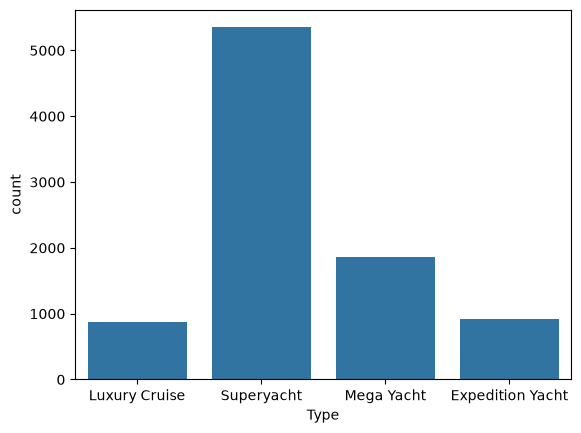

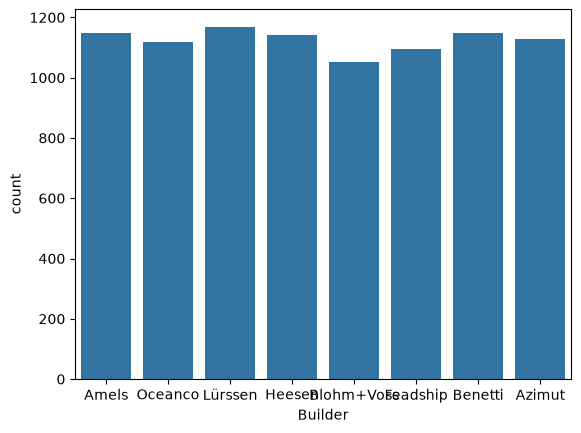

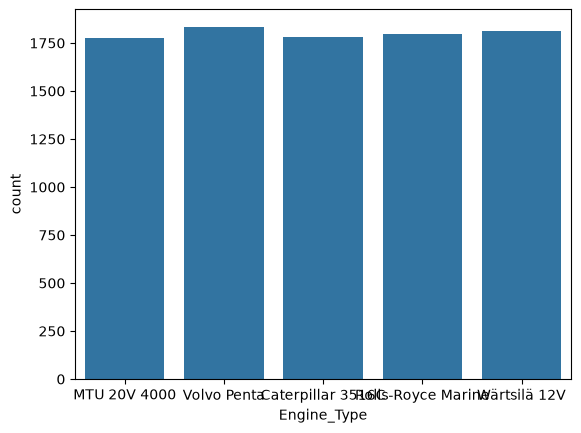

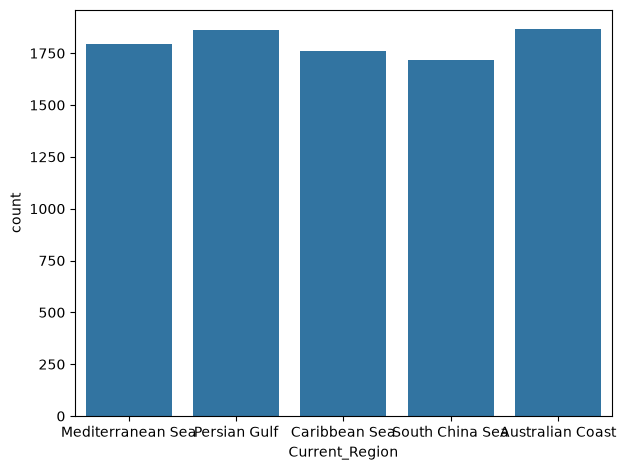

In [45]:
for i in cat_cols: 
    plt.figure()
    sns.countplot(x = df[i])

plt.tight_layout()

In [47]:
df.drop_duplicates(inplace=True)

In [48]:
df.shape

(9000, 11)

In [64]:
total_val_is = 0
for i in cat_cols: 
    print(f"----{i}----")
    print(df[i].value_counts(),"\n")
    val = df[i].nunique()
    print(f"values are {val}")
    total_val_is += val

print(f"Total new Columns are {total_val_is}.")

----Type----
Type
Superyacht          5348
Mega Yacht          1868
Expedition Yacht     915
Luxury Cruise        869
Name: count, dtype: int64 

values are 4
----Builder----
Builder
Lürssen       1168
Amels         1149
Benetti       1149
Heesen        1141
Azimut        1129
Oceanco       1117
Feadship      1096
Blohm+Voss    1051
Name: count, dtype: int64 

values are 8
----Engine_Type----
Engine_Type
Volvo Penta           1833
Wärtsilä 12V          1814
Rolls-Royce Marine    1799
Caterpillar 3516C     1780
MTU 20V 4000          1774
Name: count, dtype: int64 

values are 5
----Current_Region----
Current_Region
Australian Coast     1865
Persian Gulf         1863
Mediterranean Sea    1795
Caribbean Sea        1762
South China Sea      1715
Name: count, dtype: int64 

values are 5
Total new Columns are 22.


In [65]:
df = pd.get_dummies(df, columns=cat_cols)

In [66]:
df

,Year_Built,Length_meters,Gross_Tonnage,Top_Speed_knots,Guests_Capacity,Crew_Capacity,Estimated_Value_USD_Millions,Type_Expedition Yacht,Type_Luxury Cruise,Type_Mega Yacht,...,Engine_Type_Caterpillar 3516C,Engine_Type_MTU 20V 4000,Engine_Type_Rolls-Royce Marine,Engine_Type_Volvo Penta,Engine_Type_Wärtsilä 12V,Current_Region_Australian Coast,Current_Region_Caribbean Sea,Current_Region_Mediterranean Sea,Current_Region_Persian Gulf,Current_Region_South China Sea
0,2020,348.8,6368,26.9,1600,814,1149.30,False,True,False,...,False,True,False,False,False,False,False,True,False,False
1,2021,57.5,1321,19.5,50,26,93.19,False,False,False,...,False,False,False,True,False,False,False,False,True,False
2,2020,129.1,3550,32.3,47,33,180.04,False,False,False,...,True,False,False,False,False,False,False,False,True,False
3,2010,147.7,3392,27.5,39,26,232.14,False,False,False,...,False,False,False,True,False,False,False,False,True,False
4,2012,176.3,3248,30.7,34,22,223.96,False,False,False,...,False,False,True,False,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8995,2009,82.4,1294,27.0,34,21,108.78,False,False,False,...,False,False,False,False,True,False,False,False,True,False
8996,2024,119.7,2688,29.6,26,8,160.42,False,False,False,...,False,False,True,False,False,True,False,False,False,False
8997,2008,87.7,1435,26.1,15,4,185.29,False,False,False,...,True,False,False,False,False,False,False,True,False,False
8998,2021,149.7,4301,33.3,49,20,207.14,False,False,False,...,False,True,False,False,False,False,False,False,False,True


In [68]:
df.shape

(9000, 29)

In [70]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 29 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Year_Built                        9000 non-null   int64  
 1   Length_meters                     9000 non-null   float64
 2   Gross_Tonnage                     9000 non-null   int64  
 3   Top_Speed_knots                   9000 non-null   float64
 4   Guests_Capacity                   9000 non-null   int64  
 5   Crew_Capacity                     9000 non-null   int64  
 6   Estimated_Value_USD_Millions      9000 non-null   float64
 7   Type_Expedition Yacht             9000 non-null   bool   
 8   Type_Luxury Cruise                9000 non-null   bool   
 9   Type_Mega Yacht                   9000 non-null   bool   
 10  Type_Superyacht                   9000 non-null   bool   
 11  Builder_Amels                     9000 non-null   bool   
 12  Builder_Azimut   

In [71]:
cols_to_encode = df.select_dtypes(include=['bool']).columns.tolist()

In [72]:
cols_to_encode

['Type_Expedition Yacht',
 'Type_Luxury Cruise',
 'Type_Mega Yacht',
 'Type_Superyacht',
 'Builder_Amels',
 'Builder_Azimut',
 'Builder_Benetti',
 'Builder_Blohm+Voss',
 'Builder_Feadship',
 'Builder_Heesen',
 'Builder_Lürssen',
 'Builder_Oceanco',
 'Engine_Type_Caterpillar 3516C',
 'Engine_Type_MTU 20V 4000',
 'Engine_Type_Rolls-Royce Marine',
 'Engine_Type_Volvo Penta',
 'Engine_Type_Wärtsilä 12V',
 'Current_Region_Australian Coast',
 'Current_Region_Caribbean Sea',
 'Current_Region_Mediterranean Sea',
 'Current_Region_Persian Gulf',
 'Current_Region_South China Sea']

In [75]:
for i in cols_to_encode: 
    df[i] = df[i].astype(int)

In [76]:
df

,Year_Built,Length_meters,Gross_Tonnage,Top_Speed_knots,Guests_Capacity,Crew_Capacity,Estimated_Value_USD_Millions,Type_Expedition Yacht,Type_Luxury Cruise,Type_Mega Yacht,...,Engine_Type_Caterpillar 3516C,Engine_Type_MTU 20V 4000,Engine_Type_Rolls-Royce Marine,Engine_Type_Volvo Penta,Engine_Type_Wärtsilä 12V,Current_Region_Australian Coast,Current_Region_Caribbean Sea,Current_Region_Mediterranean Sea,Current_Region_Persian Gulf,Current_Region_South China Sea
0,2020,348.8,6368,26.9,1600,814,1149.30,0,1,0,...,0,1,0,0,0,0,0,1,0,0
1,2021,57.5,1321,19.5,50,26,93.19,0,0,0,...,0,0,0,1,0,0,0,0,1,0
2,2020,129.1,3550,32.3,47,33,180.04,0,0,0,...,1,0,0,0,0,0,0,0,1,0
3,2010,147.7,3392,27.5,39,26,232.14,0,0,0,...,0,0,0,1,0,0,0,0,1,0
4,2012,176.3,3248,30.7,34,22,223.96,0,0,0,...,0,0,1,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8995,2009,82.4,1294,27.0,34,21,108.78,0,0,0,...,0,0,0,0,1,0,0,0,1,0
8996,2024,119.7,2688,29.6,26,8,160.42,0,0,0,...,0,0,1,0,0,1,0,0,0,0
8997,2008,87.7,1435,26.1,15,4,185.29,0,0,0,...,1,0,0,0,0,0,0,1,0,0
8998,2021,149.7,4301,33.3,49,20,207.14,0,0,0,...,0,1,0,0,0,0,0,0,0,1


In [77]:
from datetime import datetime

# Get current year
current_year = datetime.now().year
print("Current year:", current_year)  # 2026

# Create new Age column
df['Yacht_Age'] = current_year - df['Year_Built']

# Check it
print(df[['Year_Built', 'Yacht_Age']].head(10))

# Drop Year_Built — no longer needed!
df = df.drop(columns=['Year_Built'])

# Verify
print("\nNew shape:", df.shape)
print("Yacht_Age min:", df['Yacht_Age'].min())  # newest yacht
print("Yacht_Age max:", df['Yacht_Age'].max())  # oldest yacht

Current year: 2026
   Year_Built  Yacht_Age
0        2020          6
1        2021          5
2        2020          6
3        2010         16
4        2012         14
5        2000         26
6        2005         21
7        2009         17
8        2018          8
9        2006         20

New shape: (9000, 29)
Yacht_Age min: 2
Yacht_Age max: 26


In [78]:
df

,Length_meters,Gross_Tonnage,Top_Speed_knots,Guests_Capacity,Crew_Capacity,Estimated_Value_USD_Millions,Type_Expedition Yacht,Type_Luxury Cruise,Type_Mega Yacht,Type_Superyacht,...,Engine_Type_MTU 20V 4000,Engine_Type_Rolls-Royce Marine,Engine_Type_Volvo Penta,Engine_Type_Wärtsilä 12V,Current_Region_Australian Coast,Current_Region_Caribbean Sea,Current_Region_Mediterranean Sea,Current_Region_Persian Gulf,Current_Region_South China Sea,Yacht_Age
0,348.8,6368,26.9,1600,814,1149.30,0,1,0,0,...,1,0,0,0,0,0,1,0,0,6
1,57.5,1321,19.5,50,26,93.19,0,0,0,1,...,0,0,1,0,0,0,0,1,0,5
2,129.1,3550,32.3,47,33,180.04,0,0,0,1,...,0,0,0,0,0,0,0,1,0,6
3,147.7,3392,27.5,39,26,232.14,0,0,0,1,...,0,0,1,0,0,0,0,1,0,16
4,176.3,3248,30.7,34,22,223.96,0,0,0,1,...,0,1,0,0,0,1,0,0,0,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8995,82.4,1294,27.0,34,21,108.78,0,0,0,1,...,0,0,0,1,0,0,0,1,0,17
8996,119.7,2688,29.6,26,8,160.42,0,0,0,1,...,0,1,0,0,1,0,0,0,0,2
8997,87.7,1435,26.1,15,4,185.29,0,0,0,1,...,0,0,0,0,0,0,1,0,0,18
8998,149.7,4301,33.3,49,20,207.14,0,0,0,1,...,1,0,0,0,0,0,0,0,1,5


In [79]:
# How many guests per crew member?
df['Guest_Crew_Ratio'] = df['Guests_Capacity'] / df['Crew_Capacity']


In [80]:
df

,Length_meters,Gross_Tonnage,Top_Speed_knots,Guests_Capacity,Crew_Capacity,Estimated_Value_USD_Millions,Type_Expedition Yacht,Type_Luxury Cruise,Type_Mega Yacht,Type_Superyacht,...,Engine_Type_Rolls-Royce Marine,Engine_Type_Volvo Penta,Engine_Type_Wärtsilä 12V,Current_Region_Australian Coast,Current_Region_Caribbean Sea,Current_Region_Mediterranean Sea,Current_Region_Persian Gulf,Current_Region_South China Sea,Yacht_Age,Guest_Crew_Ratio
0,348.8,6368,26.9,1600,814,1149.30,0,1,0,0,...,0,0,0,0,0,1,0,0,6,1.965602
1,57.5,1321,19.5,50,26,93.19,0,0,0,1,...,0,1,0,0,0,0,1,0,5,1.923077
2,129.1,3550,32.3,47,33,180.04,0,0,0,1,...,0,0,0,0,0,0,1,0,6,1.424242
3,147.7,3392,27.5,39,26,232.14,0,0,0,1,...,0,1,0,0,0,0,1,0,16,1.500000
4,176.3,3248,30.7,34,22,223.96,0,0,0,1,...,1,0,0,0,1,0,0,0,14,1.545455
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8995,82.4,1294,27.0,34,21,108.78,0,0,0,1,...,0,0,1,0,0,0,1,0,17,1.619048
8996,119.7,2688,29.6,26,8,160.42,0,0,0,1,...,1,0,0,1,0,0,0,0,2,3.250000
8997,87.7,1435,26.1,15,4,185.29,0,0,0,1,...,0,0,0,0,0,1,0,0,18,3.750000
8998,149.7,4301,33.3,49,20,207.14,0,0,0,1,...,0,0,0,0,0,0,0,1,5,2.450000


In [81]:
df['Guest_Crew_Ratio'].max()

np.float64(4.333333333333333)

In [82]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

num_cols_to_scale = [
    'Length_meters',
    'Gross_Tonnage',
    'Top_Speed_knots',
    'Guests_Capacity',
    'Crew_Capacity',
    'Yacht_Age'
    # Guest_Crew_Ratio → skip! range is only 1.4 to 4.33 ✅
]

df[num_cols_to_scale] = scaler.fit_transform(df[num_cols_to_scale])

print(df[num_cols_to_scale].describe().round(2))

       Length_meters  Gross_Tonnage  Top_Speed_knots  Guests_Capacity  \
count        9000.00        9000.00          9000.00          9000.00   
mean           -0.00           0.00            -0.00            -0.00   
std             1.00           1.00             1.00             1.00   
min            -1.33          -1.39            -1.73            -0.33   
25%            -0.72          -0.71            -0.88            -0.32   
50%            -0.14          -0.20             0.02            -0.30   
75%             0.46           0.44             0.86            -0.27   
max             3.59           4.93             1.75             5.02   

       Crew_Capacity  Yacht_Age  
count        9000.00    9000.00  
mean            0.00      -0.00  
std             1.00       1.00  
min            -0.33      -1.64  
25%            -0.31      -0.81  
50%            -0.29       0.02  
75%            -0.26       0.85  
max             6.82       1.68  


In [83]:
df

,Length_meters,Gross_Tonnage,Top_Speed_knots,Guests_Capacity,Crew_Capacity,Estimated_Value_USD_Millions,Type_Expedition Yacht,Type_Luxury Cruise,Type_Mega Yacht,Type_Superyacht,...,Engine_Type_Rolls-Royce Marine,Engine_Type_Volvo Penta,Engine_Type_Wärtsilä 12V,Current_Region_Australian Coast,Current_Region_Caribbean Sea,Current_Region_Mediterranean Sea,Current_Region_Persian Gulf,Current_Region_South China Sea,Yacht_Age,Guest_Crew_Ratio
0,3.421069,2.216838,0.337867,2.513471,2.224082,1149.30,0,1,0,0,...,0,0,0,0,0,1,0,0,-1.088960,1.965602
1,-1.061917,-0.955985,-0.949304,-0.263155,-0.255805,93.19,0,0,0,1,...,0,1,0,0,0,0,1,0,-1.227305,1.923077
2,0.039978,0.445287,1.277153,-0.268529,-0.233775,180.04,0,0,0,1,...,0,0,0,0,0,0,1,0,-1.088960,1.424242
3,0.326224,0.345960,0.442232,-0.282860,-0.255805,232.14,0,0,0,1,...,0,1,0,0,0,0,1,0,0.294491,1.500000
4,0.766366,0.255434,0.998846,-0.291817,-0.268393,223.96,0,0,0,1,...,1,0,0,0,1,0,0,0,0.017800,1.545455
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8995,-0.678716,-0.972959,0.355261,-0.291817,-0.271540,108.78,0,0,0,1,...,0,0,1,0,0,0,1,0,0.432836,1.619048
8996,-0.104684,-0.096613,0.807510,-0.306148,-0.312452,160.42,0,0,0,1,...,1,0,0,1,0,0,0,0,-1.642341,3.250000
8997,-0.597151,-0.884318,0.198713,-0.325853,-0.325040,185.29,0,0,0,1,...,0,0,0,0,0,1,0,0,0.571181,3.750000
8998,0.357003,0.917407,1.451095,-0.264946,-0.274687,207.14,0,0,0,1,...,0,0,0,0,0,0,0,1,-1.227305,2.450000


In [85]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 30 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Length_meters                     9000 non-null   float64
 1   Gross_Tonnage                     9000 non-null   float64
 2   Top_Speed_knots                   9000 non-null   float64
 3   Guests_Capacity                   9000 non-null   float64
 4   Crew_Capacity                     9000 non-null   float64
 5   Estimated_Value_USD_Millions      9000 non-null   float64
 6   Type_Expedition Yacht             9000 non-null   int64  
 7   Type_Luxury Cruise                9000 non-null   int64  
 8   Type_Mega Yacht                   9000 non-null   int64  
 9   Type_Superyacht                   9000 non-null   int64  
 10  Builder_Amels                     9000 non-null   int64  
 11  Builder_Azimut                    9000 non-null   int64  
 12  Builder_Benetti  